## DiffGSP tutorial 2: mouse kidney Visium dataset

This tutorial demonstrates how to apply **DiffGSP** to a mouse kidney Visium dataset.
The dataset can be obtained from the [original study](https://www.10xgenomics.com/datasets/adult-mouse-kidney-ffpe-1-standard-1-3-0). For convenience, we have provided the dataset in Google Drive. You can download it directly to run this tutorial: [download the dataset](https://drive.google.com/drive/folders/1Mq_1C2iYgpTCCP7Ko2SHRwwZO3yNgLga?usp=sharing).

In [1]:
import DiffGSP as dg
import torch
import os
import scanpy as sc
from pathlib import Path
import matplotlib.pyplot as plt

device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda:1


### 1. Define input and output paths

In [2]:
# Please download the dataset and specify the path here
data_dir = Path("/home/liujixin/datasets/Visium")
res_dir = Path("/home/liujixin/project/DiffGSP/results/Visium")
data_name = "1.3.0_Visium_FFPE_Mouse_Kidney"
data_dir = data_dir / data_name
res_dir = res_dir / data_name
res_dir.mkdir(parents=True, exist_ok=True)

### 2. Load and preprocess the Visium data


In [3]:
# load data
adata = sc.read_visium(data_dir,
                       count_file=data_name + '_raw_feature_bc_matrix.h5')
adata.var_names_make_unique()
# prefilter
adata = adata[:, dg.prefilter_genes(adata, min_cells=10)]
svgs = dg.select_svgs(adata, svg_method='gft_top', n_top=2000)
adata = adata[:, svgs]
adata

View of AnnData object with n_obs × n_vars = 4992 × 2000
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'

Note that adata.obs['in_tissue'] is required for parameter learning. If there are no out-of-tissue spots in this data, please give the parameters manually.


### 3. Save the preprocessed original data

In [4]:
adata_raw = adata.copy()

adata_raw.write_h5ad(
    res_dir / f"{data_name}_Original.h5ad"
)

### 4. Run DiffGSP

The parameter `inv_cutoff` controls the extent of inverse diffusion and corresponds to the stability ratio used to determine the reconstruction cutoff. Two settings can be used:
- `inv_cutoff="auto"`: automatically determines the cutoff from the stability curve.
- A numerical value, such as `inv_cutoff=1.2`: manually specifies the cutoff.

For this mouse kidney Visium dataset, the cutoff is automatically determined using the stability curve.

In [5]:
# load preprocessed data
adata = sc.read_h5ad(
    res_dir / f"{data_name}_Original.h5ad"
)

k = 5  # controls the diffusion step
inv = "auto"
adata, optimal_solution, loss_list, constant = dg.run_diffgsp(
    adata,
    gene_network=False,
    k=k,
    device=device,
    method="BFGS",
    data_type="Visium",
    inv_cutoff=inv
)
# save DiffGSP output
adata.write_h5ad(
    res_dir / f"{data_name}_DiffGSP.h5ad"
)

Training:   7%|▉            | 7/100 [01:26<19:04, 12.30s/it, Loss=tensor(163.2650, device='cuda:1')]


New para 0.100903936
Current parameters: 	 [np.float32(0.100903936), array(0.005, dtype=float32)]


## 5. Downstream analysis

#### Visualization of representative genes

First, we visualize several representative genes to compare their spatial expression patterns before and after diffusion correction.

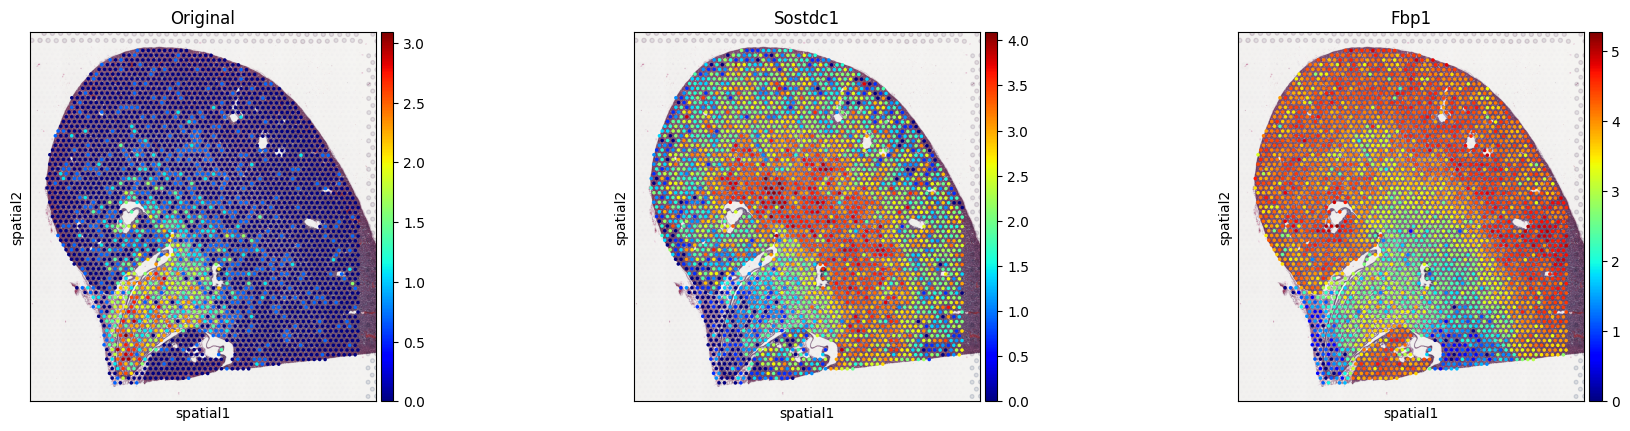

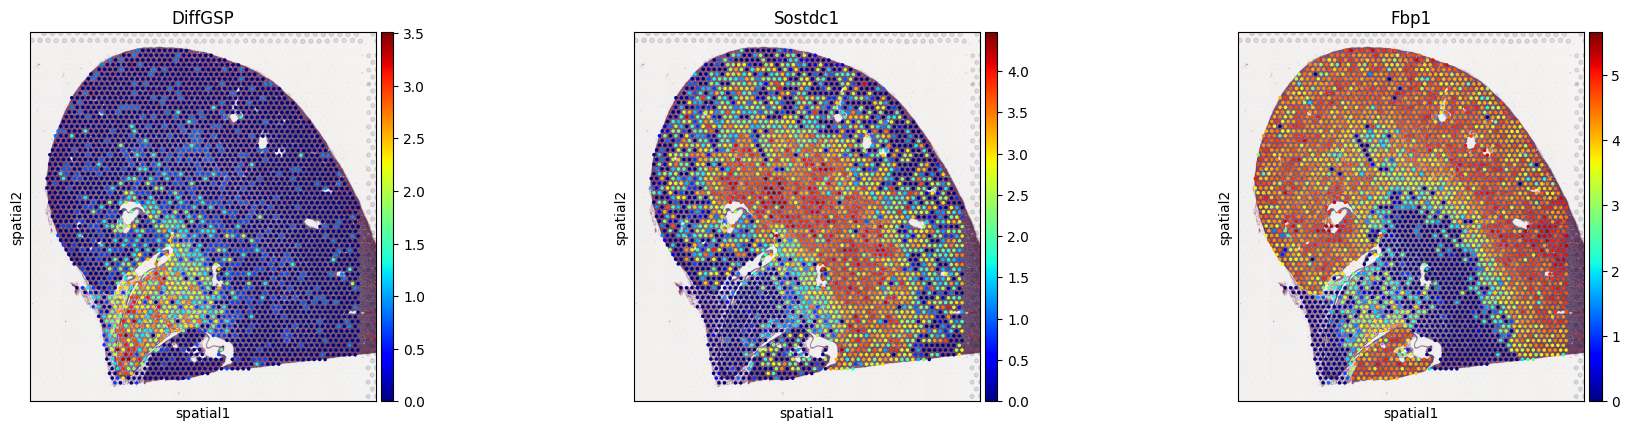

In [6]:
# load data
adata_orig = sc.read_h5ad(
    res_dir / f"{data_name}_Original.h5ad"
)

adata_diff = sc.read_h5ad(
    res_dir / f"{data_name}_DiffGSP.h5ad"
)

# log transformation for visualization
sc.pp.log1p(adata_orig)
sc.pp.log1p(adata_diff)

# keep spots in tissue
in_tissue_spots = adata_orig.obs_names[adata_orig.obs['in_tissue'] == 1]
adata_orig = adata_orig[in_tissue_spots]
adata_diff = adata_diff[in_tissue_spots]

# visualization of representative genes
gene_list = [
    "Wnt4",
    "Sostdc1",
    "Fbp1"
]
sc.pl.spatial(
    adata_orig,
    color=gene_list,
    cmap="jet",
    title="Original"
)
sc.pl.spatial(
    adata_diff,
    color=gene_list,
    cmap="jet",
    title="DiffGSP"
)

#### Visualization of a PyWGCNA-identified gene module

Next, we visualize a representative gene module identified by PyWGCNA.
The selected module is associated with cortex (GM6) and contains the following genes: Aldob, Fth1, Galnt11, and Pdzk1.

In [7]:
# genes in the adipose-related module
module_genes = [
    "Aldob",
    "Fth1",
    "Galnt11",
    "Pdzk1",
]

Visualize individual genes before DiffGSP's processing


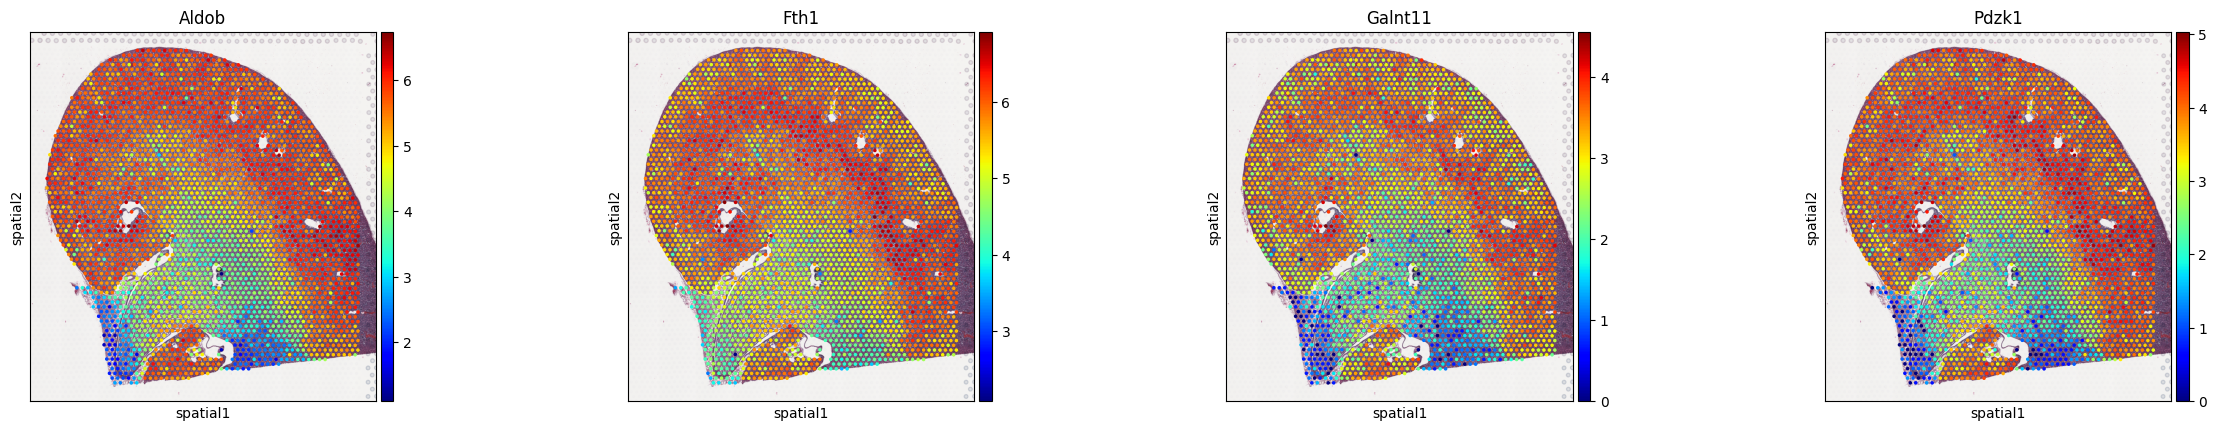

In [8]:
sc.pl.spatial(
    adata_orig,
    color=module_genes,
    cmap="jet",
)

Visualize individual genes after DiffGSP's processing

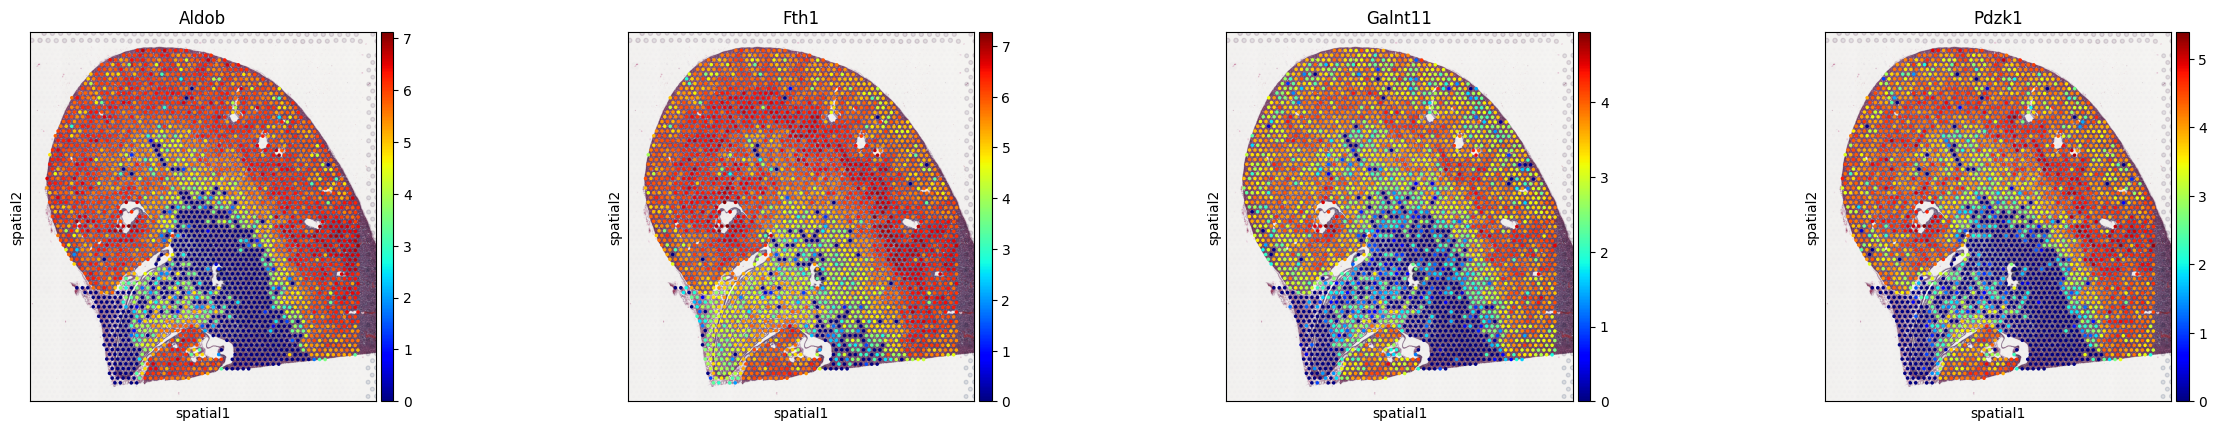

In [9]:
sc.pl.spatial(
    adata_diff,
    color=module_genes,
    cmap="jet",
)